In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.inspection import permutation_importance
from src.data import load_data
from src.config import RANDOM_STATE, CV_DIR, FIG_DIR
from src.pipelines import get_final
from src.feature_groups import group_columns

# Tải dữ liệu train và chia thêm 20% làm tập validation để đánh giá độ quan trọng đặc trưng
X_train, _, y_train, _, labels = load_data()
Xa, Xb, ya, yb = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

# Huấn luyện mô hình trên phần Xa, ya và tính điểm Macro-F1 mốc trên Xb, yb
model = get_final()
model.fit(Xa, ya)

pred_val = model.predict(Xb)
base = f1_score(yb, pred_val, average="macro")
print("Macro-F1 validation:", round(base, 4))

Macro-F1 validation: 0.9652


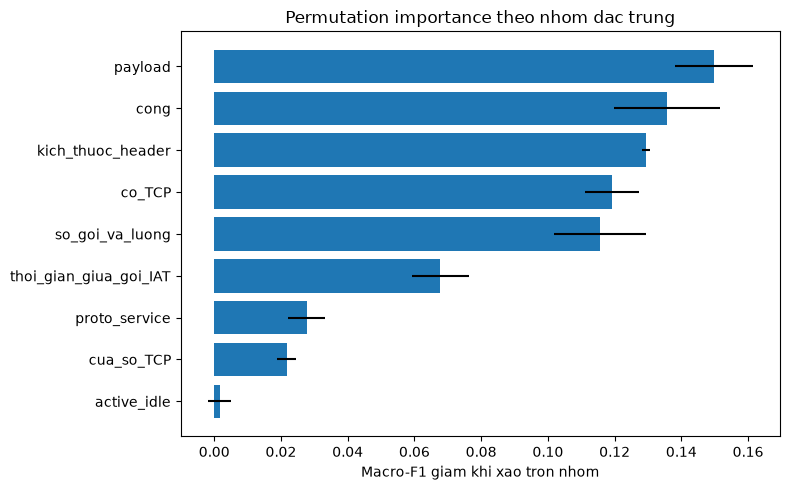

,nhom,so_cot,giam_macro_f1_tb,std
4,payload,11,0.1497,0.0117
0,cong,2,0.1357,0.0158
2,kich_thuoc_header,4,0.1294,0.0013
3,co_TCP,9,0.1191,0.0081
1,so_goi_va_luong,13,0.1157,0.0138
5,thoi_gian_giua_goi_IAT,10,0.0678,0.0085
8,proto_service,13,0.0277,0.0056
7,cua_so_TCP,3,0.0217,0.0029
6,active_idle,5,0.0016,0.0035


In [2]:
rng = np.random.default_rng(RANDOM_STATE)
nhom_cols = group_columns(X_train.columns)

rows = []
for g, cols in nhom_cols.items():
    giam_list = []

    # Lặp 5 lần để lấy trung bình và độ lệch chuẩn mức giảm Macro-F1
    for _ in range(5):
        Xp = Xb.copy()
        perm = rng.permutation(len(Xp))

        # Xáo trộn thứ tự hàng của toàn bộ các cột thuộc nhóm g
        shuffled_values = Xb[cols].to_numpy()[perm]
        Xp[cols] = shuffled_values

        pred_p = model.predict(Xp)
        score_p = f1_score(yb, pred_p, average="macro")
        giam_list.append(base - score_p)

    row_info = {
        "nhom": g,
        "so_cot": len(cols),
        "giam_macro_f1_tb": np.mean(giam_list),
        "std": np.std(giam_list),
    }
    rows.append(row_info)

# Tạo bảng tổng hợp, sắp xếp nhóm làm giảm điểm nhiều nhất lên đầu và làm tròn
nhom = pd.DataFrame(rows)
nhom = nhom.sort_values("giam_macro_f1_tb", ascending=False)
nhom = nhom.round(4)
nhom.to_csv(CV_DIR / "perm_importance_groups.csv", index=False)

# Đảo ngược thứ tự để khi vẽ barh từ dưới lên trên thì nhóm quan trọng nhất nằm ở trên cùng
nhom_plot = nhom.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    nhom_plot["nhom"],
    nhom_plot["giam_macro_f1_tb"],
    xerr=nhom_plot["std"],
)
ax.set_xlabel("Macro-F1 giam khi xao tron nhom")
ax.set_title("Permutation importance theo nhom dac trung")

plt.tight_layout()
plt.savefig(FIG_DIR / "perm_importance_groups.png", dpi=300, bbox_inches="tight")
plt.show()

nhom

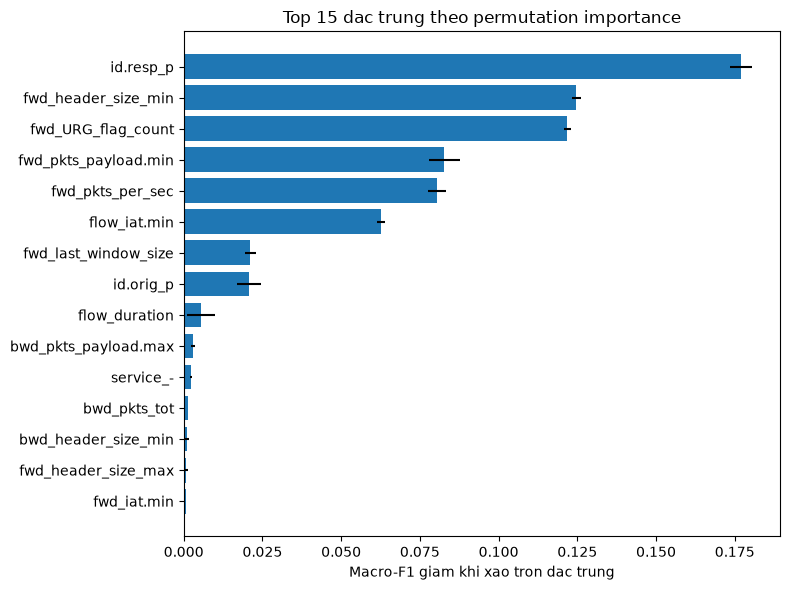

,dac_trung,giam_macro_f1,std
1,id.resp_p,0.176849,0.003501
9,fwd_header_size_min,0.124717,0.001498
17,fwd_URG_flag_count,0.121807,0.001189
21,fwd_pkts_payload.min,0.082749,0.004954
6,fwd_pkts_per_sec,0.080308,0.002867
40,flow_iat.min,0.062569,0.001229
56,fwd_last_window_size,0.021187,0.001671
0,id.orig_p,0.020654,0.003815
2,flow_duration,0.005509,0.004346
27,bwd_pkts_payload.max,0.002956,0.000576


In [3]:
# Tính permutation importance cho từng đặc trưng trên tập validation (Xb, yb)
pi = permutation_importance(
    model,
    Xb,
    yb,
    scoring="f1_macro",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

# Tổng hợp kết quả vào DataFrame và sắp xếp theo mức giảm Macro-F1 từ cao đến thấp
dt = pd.DataFrame({
    "dac_trung": X_train.columns,
    "giam_macro_f1": pi.importances_mean,
    "std": pi.importances_std,
})
dt = dt.sort_values("giam_macro_f1", ascending=False)
dt.to_csv(CV_DIR / "perm_importance_features.csv", index=False)

# Lấy top 15 đặc trưng quan trọng nhất và đảo thứ tự để vẽ barh từ trên xuống dưới
top = dt.head(15)
top_plot = top.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(
    top_plot["dac_trung"],
    top_plot["giam_macro_f1"],
    xerr=top_plot["std"],
)
ax.set_xlabel("Macro-F1 giam khi xao tron dac trung")
ax.set_title("Top 15 dac trung theo permutation importance")

plt.tight_layout()
plt.savefig(FIG_DIR / "perm_importance_features.png", dpi=300, bbox_inches="tight")
plt.show()

dt.head(15)